In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.game import *
from src.piece import *
from src.util import * 

In [76]:
def solvePuzzle(board, indices, pieces):
    """ 
    Recursive Function that uses the board and available pieces as it's input
    In each call it takes a piece and brute force tries it at every triangle. Then rotates it. 
    If it ever succeeds it calls itself with 1 less piece. If it fails it returns itself witht the piece
    still available, then it continues the previous pieces brute force.
    """
    for piece in pieces:
        if not piece.placed:
            break
    if piece.placed:
        # print("Piece Placed")
        if isSolved(board):
            print('Game Done')
            return board, pieces, True
        return board, pieces, False
    for indx in range(indices.size):
        board, placed = placeIfValid(board, indices[indx], piece)
        if placed:
            # print("Placed Piece")
            piece.placed = True
            board, pieces, solved = solvePuzzle(board, indices, pieces)
            if solved:
                return board, pieces, solved
            removePiece(board, piece)
            # print("Removed Piece")
            piece.placed = False
    piece.rotateForwards()
    if piece.name == "DarkGreen5": print("Rotated ", piece.rotation)
    if piece.rotation <= 6:
        board, pieces, solved = solvePuzzle(board, indices, pieces)
        if solved:
            return board, pieces, solved
    piece.rotateBackwords()
    if not piece.flipped:
        piece.flipPiece()
        board, pieces, solved = solvePuzzle(board, indices, pieces)
        if solved:
            return board, pieces, solved
        piece.flipPiece()
    return board, pieces, False

In [2]:
# Setup Game
board, pieces = setupGame()
pieces = setPreviousPiece(pieces)
pieces = reorderPieces(pieces)
indices = getBoardIndices(board)

The Dice Rolls are 24, 4, 38, 31, 18, 15, 29


In [88]:
# Solve Game (Non Function for Debugging)
# solvedBoard, pieces, solved = solvePuzzle(board, indices, pieces)
# previous_piece = None
while not isSolved(board):
# for _ in range(50):
    # First Non-Placed Piece.
    for piece in pieces:
        if not piece.placed:
            break
    if piece.last_indx is None: starting_indx = 0
    else: starting_indx = piece.last_indx
    for indx in range(starting_indx + 1, indices.size):
        board, placed = placeIfValid(board, indices[indx], piece)
        if placed:
            if piece.name == 'LightGreen5': print(f"Placed LightGreen5 at {indices[indx]} w/ Roation:{piece.rotation} & Flipped:{piece.flipped}")
            piece.placed = True
            piece.last_indx = indx
            break
    if not placed:
        if piece.rotation == 5 and piece.flipped:
            board = removePiece(board, piece.previous_piece)
            # print("Removed Piece")
            piece.previous_piece.placed = False
        if piece.rotation == 5:
            piece.rotateForwards()
            piece.rotation = 1
            piece.flipPiece()
            piece.last_indx = 0
        else:
            piece.rotateForwards()
            piece.rotation += 1
            piece.last_indx = 0

Placed LightGreen5 at (1.0, -2.0) w/ Roation:2 & Flipped:False
Placed LightGreen5 at (0.5, -1.0) w/ Roation:3 & Flipped:False
Placed LightGreen5 at (2.0, 0.0) w/ Roation:3 & Flipped:False


<function matplotlib.pyplot.show(close=None, block=None)>

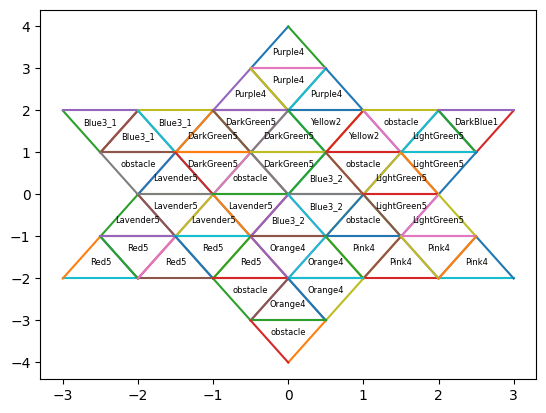

In [ ]:
plotBoard(board)

<function matplotlib.pyplot.show(close=None, block=None)>

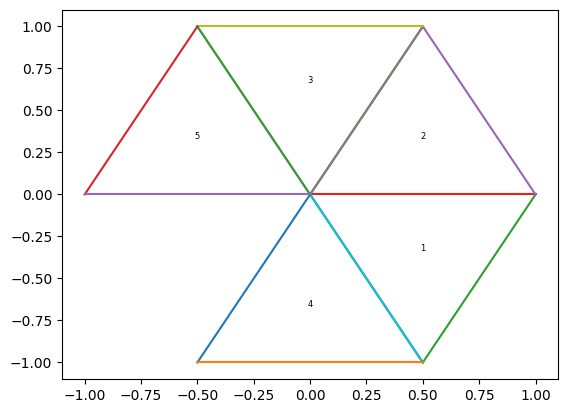

In [153]:
# Plot a Piece
fig, ax = plt.subplots()
indx = 0
for triangle in pieces[indx].data.index:
    ax.plot(
        [pieces[indx].data.loc[triangle, "v1_x"], pieces[indx].data.loc[triangle, "v2_x"]],
        [pieces[indx].data.loc[triangle, "v1_y"], pieces[indx].data.loc[triangle, "v2_y"]]
    )
    ax.plot(
        [pieces[indx].data.loc[triangle, "v2_x"], pieces[indx].data.loc[triangle, "v3_x"]],
        [pieces[indx].data.loc[triangle, "v2_y"], pieces[indx].data.loc[triangle, "v3_y"]]
    )
    ax.plot(
        [pieces[indx].data.loc[triangle, "v1_x"], pieces[indx].data.loc[triangle, "v3_x"]],
        [pieces[indx].data.loc[triangle, "v1_y"], pieces[indx].data.loc[triangle, "v3_y"]]
    )
    ax.annotate(pieces[indx].data.loc[triangle].name, (pieces[indx].data.loc[triangle, "center_x"], pieces[indx].data.loc[triangle, "center_y"]), size=6,  ha='center')
plt.show

In [152]:
pieces[indx].data.loc[triangle].name

np.int64(5)